In [15]:
import urllib.request

model_url = "https://github.com/mlxdrr/Medical-Image-Classifier/raw/refs/heads/main/medical_image_classifier.pth"

urllib.request.urlretrieve(model_url,"medical_image_classifier.pth")

print("Model downloaded successfully!")

Model downloaded successfully!


In [16]:
import torch
from torch import nn
from torchvision import transforms
from torchvision.models import mobilenet_v3_small

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(1024, 2)

model.load_state_dict(torch.load("medical_image_classifier.pth",map_location=device,weights_only=True))

model = model.to(device)
model.eval()

transform = transforms.Compose([transforms.Resize((224, 224)),transforms.ToTensor(),transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])])

class_names = ["NORMAL", "PNEUMONIA"]

print("AI model loaded successfully!")

AI model loaded successfully!


Saving chest xray.png to chest xray.png


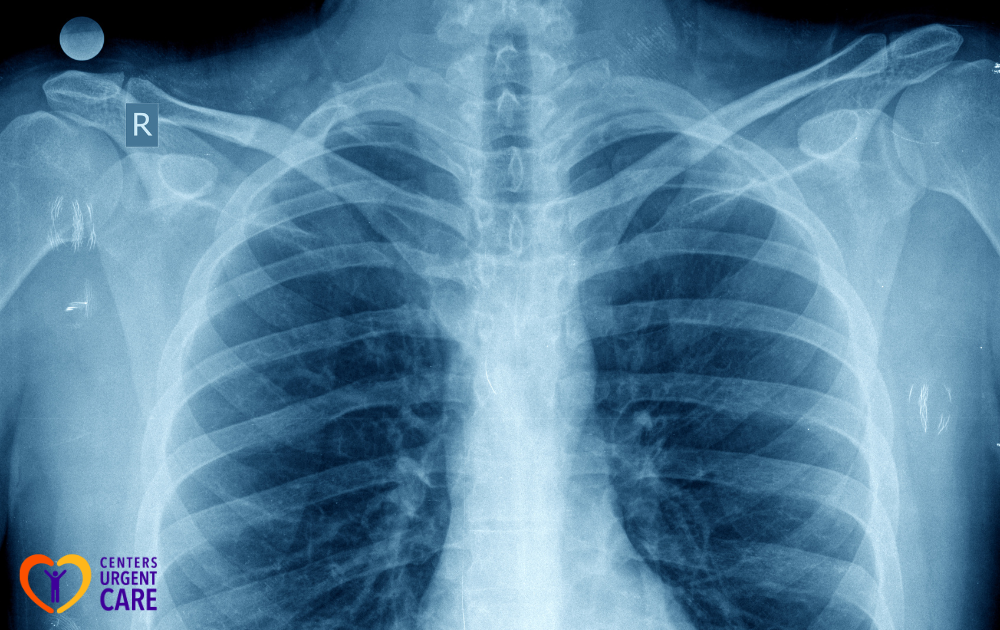

Predicted category: NORMAL
Educational demonstration only — not a medical diagnosis.


In [17]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

for filename, data in uploaded.items():
    image = Image.open(io.BytesIO(data)).convert("RGB")
    display(image)

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        prediction = torch.argmax(outputs, dim=1).item()

    print("Predicted category:", class_names[prediction])
    print("Educational demonstration only — not a medical diagnosis.")